<a href="https://colab.research.google.com/github/fhs8426018-hub/i2wi-learning-fhs8426018-hub/blob/main/unit16.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.decomposition import PCA
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, roc_auc_score, confusion_matrix

# 図の色を先に決めておく（BLUE=主役、ORANGE=強調・注意、INK=文字と基準線、MUTED=補助）。以降の図で同じ意味に使う
BLUE, ORANGE, INK, MUTED = "#2a78d6", "#eb6834", "#0b0b0b", "#898781"
# 図の見た目をまとめて設定（解像度、上と右の枠線を消す、薄い罫線）。内容には関係しない
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": INK, "ytick.color": INK, "axes.grid": True,
    "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
})

raw = load_breast_cancer(as_frame=True)
X = raw.data                                  # 特徴量 30 個（表）
y = (raw.target == 0).astype(int)             # 悪性 = 1、良性 = 0 にそろえる。scikit-learn の元の値は 0=悪性、1=良性で逆。感度（悪性を見逃さない割合）を自然に読むため
names = list(X.columns)
print(X.shape, "malignant:", int(y.sum()), "benign:", int((y == 0).sum()))

(569, 30) malignant: 212 benign: 357


In [2]:
Xs = StandardScaler().fit_transform(X)                           # 特徴量の単位が違う（面積は数百、滑らかさは 0.1）ので、平均 0・標準偏差 1 にそろえる。そろえないと、面積だけで分かれる
km = KMeans(n_clusters=2, n_init=10, random_state=0).fit(Xs)     # 2 つに分ける。2 = 良性・悪性の 2 群を期待した、人が決めた値。n_init=10 は初期値を 10 通り試す（既定の値）。random_state=0 は人が決めた値
tab = pd.crosstab(pd.Series(km.labels_, name="cluster"), pd.Series(np.where(y == 1, "malignant", "benign"), name="true label"))
print(tab)
print("ARI:", round(adjusted_rand_score(y, km.labels_), 3), "（1 = 完全に一致、0 = 偶然と同じ）")

true label  benign  malignant
cluster                      
0              339         36
1               18        176
ARI: 0.654 （1 = 完全に一致、0 = 偶然と同じ）


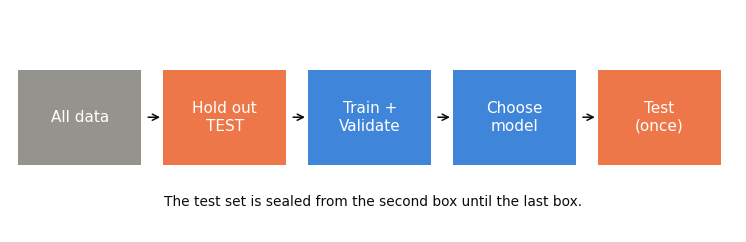

In [3]:
# 図の読み方: 左から右へ進む。上の列は「使えるデータ」の分け方、下の列は「やること」。
# テスト用（オレンジ）は、最初に取り分けて、最後の「Test」まで一度も触らない。検証用（青）は、訓練用の中で作る。
fig, ax = plt.subplots(figsize=(8.5, 2.6)); ax.axis("off"); ax.set_xlim(0, 10); ax.set_ylim(0, 3)
boxes = [(0.1, "All data", MUTED), (2.1, "Hold out\nTEST", ORANGE), (4.1, "Train +\nValidate", BLUE), (6.1, "Choose\nmodel", BLUE), (8.1, "Test\n(once)", ORANGE)]
for x0, t, c in boxes:
    ax.add_patch(plt.Rectangle((x0, 0.9), 1.7, 1.3, fc=c, ec="none", alpha=0.9)); ax.text(x0 + 0.85, 1.55, t, ha="center", va="center", color="white", fontsize=10)
for x0 in (1.85, 3.85, 5.85, 7.85):
    ax.annotate("", xy=(x0 + 0.25, 1.55), xytext=(x0, 1.55), arrowprops=dict(arrowstyle="->", color=INK))
ax.text(5.0, 0.35, "The test set is sealed from the second box until the last box.", ha="center", color=INK, fontsize=9)
plt.show()

In [4]:
print("例数:", len(X), "／ 悪性:", int(y.sum()), f"({y.mean():.1%})", "／ 良性:", int((y == 0).sum()), f"({1 - y.mean():.1%})")
print("欠損値の総数:", int(X.isna().sum().sum()), "／ 完全に同じ行の数:", int(X.duplicated().sum()))
# 「mean」の 10 特徴について、良性・悪性ごとの平均（標準偏差）を並べる。ほかの 20 個（SE・worst）も同じ形で出せる
mean_cols = [c for c in names if c.startswith("mean ")]
tbl = pd.DataFrame({
    "benign mean (SD)": X.loc[y == 0, mean_cols].apply(lambda s: f"{s.mean():.3g} ({s.std():.2g})"),
    "malignant mean (SD)": X.loc[y == 1, mean_cols].apply(lambda s: f"{s.mean():.3g} ({s.std():.2g})"),
    "Welch p": [stats.ttest_ind(X.loc[y == 0, c], X.loc[y == 1, c], equal_var=False).pvalue for c in mean_cols],
})
tbl["Welch p"] = tbl["Welch p"].map(lambda p: "<0.001" if p < 0.001 else f"{p:.3f}")   # p値は 0.001 未満なら「<0.001」と書く（論文の通例）
print(tbl.to_string())
# 特徴量どうしの相関。|r| > 0.9 の組が多いと、似た情報が重複している（7 節の特徴選択・次元圧縮の動機）
corr = X.corr().abs().values
iu = np.triu_indices(len(names), 1)
print("\n特徴量の組", len(iu[0]), "のうち、|r| > 0.9 の組:", int((corr[iu] > 0.9).sum()))

例数: 569 ／ 悪性: 212 (37.3%) ／ 良性: 357 (62.7%)
欠損値の総数: 0 ／ 完全に同じ行の数: 0
                       benign mean (SD) malignant mean (SD) Welch p
mean radius                  12.1 (1.8)          17.5 (3.2)  <0.001
mean texture                   17.9 (4)          21.6 (3.8)  <0.001
mean perimeter                78.1 (12)            115 (22)  <0.001
mean area                 463 (1.3e+02)       978 (3.7e+02)  <0.001
mean smoothness          0.0925 (0.013)       0.103 (0.013)  <0.001
mean compactness         0.0801 (0.034)       0.145 (0.054)  <0.001
mean concavity           0.0461 (0.043)       0.161 (0.075)  <0.001
mean concave points      0.0257 (0.016)       0.088 (0.034)  <0.001
mean symmetry             0.174 (0.025)       0.193 (0.028)  <0.001
mean fractal dimension  0.0629 (0.0067)     0.0627 (0.0076)   0.767

特徴量の組 435 のうち、|r| > 0.9 の組: 21


In [5]:
# テスト用 20% を最初に取り分ける。20% は人が決めた値（よく使われる 10〜30% の範囲。根拠のある最適値は無い）。random_state=0 も人が決めた値
Xdev, Xte, ydev, yte = train_test_split(X, y, test_size=0.2, stratify=y, random_state=0)
print("開発用:", len(ydev), "（悪性", int(ydev.sum()), "）／ テスト用:", len(yte), "（悪性", int(yte.sum()), "）")
# 以降、開発用の中だけで、検証を繰り返す。モデルは「標準化 → ロジスティック回帰」を 1 つにつなぐ（Pipeline）。つなぐ理由は、下の「漏れ」で分かる
lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))   # max_iter=1000 は、収束の打ち切り回数。既定の 100 では足りないことがあるため、人が決めた値

開発用: 455 （悪性 170 ）／ テスト用: 114 （悪性 42 ）


ホールドアウト 1 回の正解率: 平均 0.983、標準偏差 0.012、最小 0.939、最大 1.000
5 分割交差検証の平均正解率: 平均 0.981、標準偏差 0.004、最小 0.967、最大 0.989


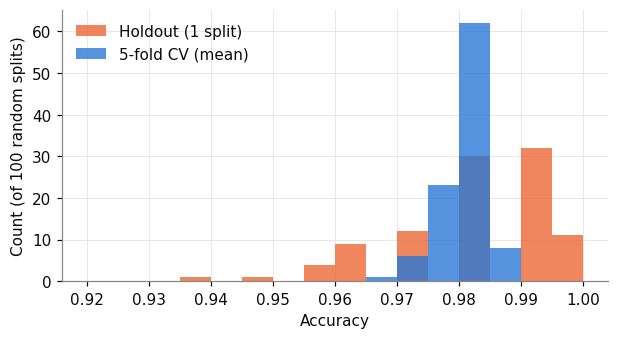

In [6]:
# 同じ開発用を、100 通りの乱数で「訓練 75%／検証 25%」に分け、検証用の正解率を 100 個並べる。ホールドアウトの揺れを見る
hold = []
for seed in range(100):                      # 100 は人が決めた値（揺れの幅が見えれば十分）
    a, b, ya, yb = train_test_split(Xdev, ydev, test_size=0.25, stratify=ydev, random_state=seed)
    hold.append(lr.fit(a, ya).score(b, yb))
hold = np.array(hold)
# 5 分割交差検証の正解率（1 回分 = 5 個の平均）。分け方の乱数を 100 通りに変えて、その平均の揺れも見る
cv_means = []
for seed in range(100):
    cv_means.append(cross_val_score(lr, Xdev, ydev, cv=StratifiedKFold(5, shuffle=True, random_state=seed)).mean())
cv_means = np.array(cv_means)
print(f"ホールドアウト 1 回の正解率: 平均 {hold.mean():.3f}、標準偏差 {hold.std():.3f}、最小 {hold.min():.3f}、最大 {hold.max():.3f}")
print(f"5 分割交差検証の平均正解率: 平均 {cv_means.mean():.3f}、標準偏差 {cv_means.std():.3f}、最小 {cv_means.min():.3f}、最大 {cv_means.max():.3f}")

# 図の読み方: 横軸は正解率、縦軸は 100 通りの分け方のうち何回その値になったか。
# オレンジ（ホールドアウト 1 回）は幅が広い＝「運の良い分け方」「悪い分け方」で結論が変わる。青（5 分割交差検証の平均）は幅が狭い。
fig, ax = plt.subplots(figsize=(6.4, 3.2))
bins = np.linspace(0.92, 1.0, 17)
ax.hist(hold, bins=bins, color=ORANGE, alpha=0.8, label="Holdout (1 split)")
ax.hist(cv_means, bins=bins, color=BLUE, alpha=0.8, label="5-fold CV (mean)")
ax.set_xlabel("Accuracy"); ax.set_ylabel("Count (of 100 random splits)"); ax.legend(frameon=False)
plt.show()

In [7]:
rng = np.random.default_rng(0)                # 乱数の種。0 は人が決めた値
n = len(ydev)
oob_fracs, oob_acc = [], []
for _ in range(200):                          # 200 回。人が決めた値（OOB の平均が落ち着けば十分）
    idx = rng.integers(0, n, n)               # n 個を、重複を許して選ぶ
    oob = np.setdiff1d(np.arange(n), idx)     # 1 度も選ばれなかった例
    oob_fracs.append(len(oob) / n)
    m = lr.fit(Xdev.iloc[idx], ydev.iloc[idx])
    oob_acc.append(m.score(Xdev.iloc[oob], ydev.iloc[oob]))
print(f"OOB の割合: 平均 {np.mean(oob_fracs):.3f}（理論値 1/e = {np.exp(-1):.3f}）")
print(f"OOB の正解率: 平均 {np.mean(oob_acc):.3f}、2.5〜97.5 パーセンタイル {np.percentile(oob_acc, 2.5):.3f}〜{np.percentile(oob_acc, 97.5):.3f}")

OOB の割合: 平均 0.367（理論値 1/e = 0.368）
OOB の正解率: 平均 0.977、2.5〜97.5 パーセンタイル 0.952〜1.000


In [8]:
cv5 = StratifiedKFold(5, shuffle=True, random_state=0)   # 5 分割。5 は人が決めた値（よく使われる 5 か 10）
leak, proper = [], []
for r in range(20):                                       # 20 回くり返す（1 回だと乱数の運かもしれないため）。20 は人が決めた値
    g = np.random.default_rng(r)
    Xn = g.normal(size=(100, 2000))                       # 100 例 × 2000 個の乱数の特徴量。ラベルとは無関係
    yn = g.integers(0, 2, 100)                            # 乱数のラベル。本当の正解率は 50%
    # 漏れあり: ラベルとの相関が高い 20 個を、全データで先に選んでから、交差検証
    Xk = SelectKBest(f_classif, k=20).fit_transform(Xn, yn)
    leak.append(cross_val_score(LogisticRegression(max_iter=1000), Xk, yn, cv=cv5).mean())
    # 漏れなし: 特徴選択を、訓練用の中だけでやる（Pipeline に入れる）
    pipe = make_pipeline(SelectKBest(f_classif, k=20), LogisticRegression(max_iter=1000))
    proper.append(cross_val_score(pipe, Xn, yn, cv=cv5).mean())
print(f"(A) 乱数データ（本当は 0.50）: 漏れあり {np.mean(leak):.3f}／漏れなし {np.mean(proper):.3f}")

# (B) 実データで、標準化を分割の前に全データでやった場合と、Pipeline に入れた場合
auc_leak = cross_val_score(LogisticRegression(max_iter=1000), StandardScaler().fit_transform(Xdev), ydev, cv=cv5, scoring="roc_auc").mean()
auc_pipe = cross_val_score(lr, Xdev, ydev, cv=cv5, scoring="roc_auc").mean()
print(f"(B) 実データの AUC: 標準化を先にやった {auc_leak:.4f}／Pipeline {auc_pipe:.4f}")

(A) 乱数データ（本当は 0.50）: 漏れあり 0.838／漏れなし 0.515
(B) 実データの AUC: 標準化を先にやった 0.9918／Pipeline 0.9915


In [9]:
models = {
    "Logistic regression": lr,
    "SVM (RBF)": make_pipeline(StandardScaler(), SVC()),
    "k-NN (k=5)": make_pipeline(StandardScaler(), KNeighborsClassifier()),   # k=5 は scikit-learn の既定の値。人が決めた値ではなく、既定
    "Decision tree": DecisionTreeClassifier(random_state=0),                  # 木は、標準化が要らない
    "Random forest": RandomForestClassifier(random_state=0),
}
rows = []
for name, m in models.items():
    s = cross_val_score(m, Xdev, ydev, cv=cv5, scoring="roc_auc")             # 5 個の AUC
    rows.append((name, s.mean(), s.std()))
res = pd.DataFrame(rows, columns=["model", "mean AUC", "SD over folds"]).set_index("model")
print(res.round(4).to_string())

                     mean AUC  SD over folds
model                                       
Logistic regression    0.9915         0.0090
SVM (RBF)              0.9949         0.0057
k-NN (k=5)             0.9825         0.0152
Decision tree          0.9231         0.0246
Random forest          0.9936         0.0038


In [10]:
grid = GridSearchCV(lr, {"logisticregression__C": [0.001, 0.01, 0.1, 1, 10, 100]},   # 10 倍刻みの 6 点。人が決めた範囲（対数で並べるのが通例）
                    cv=cv5, scoring="roc_auc").fit(Xdev, ydev)
for c, s in zip(grid.param_grid["logisticregression__C"], grid.cv_results_["mean_test_score"]):
    print(f"C = {c:<7} 検証の AUC = {s:.4f}")
print("選ばれた C:", grid.best_params_["logisticregression__C"], "／ AUC =", round(grid.best_score_, 4))

C = 0.001   検証の AUC = 0.9871
C = 0.01    検証の AUC = 0.9935
C = 0.1     検証の AUC = 0.9944
C = 1       検証の AUC = 0.9915
C = 10      検証の AUC = 0.9885
C = 100     検証の AUC = 0.9856
選ばれた C: 0.1 ／ AUC = 0.9944


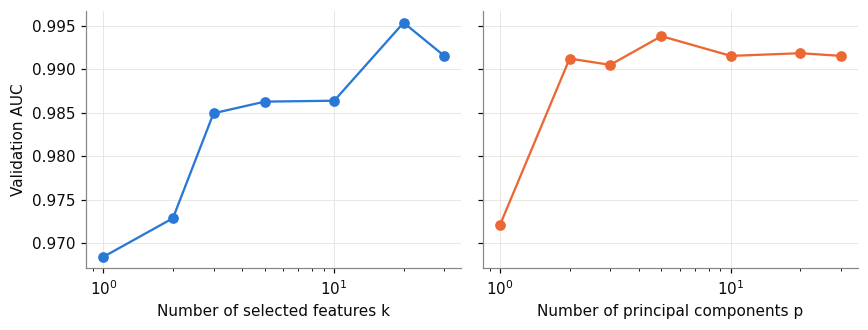

k  : {1: np.float64(0.9684), 2: np.float64(0.9729), 3: np.float64(0.9849), 5: np.float64(0.9863), 10: np.float64(0.9864), 20: np.float64(0.9954), 30: np.float64(0.9915)}
p  : {1: np.float64(0.9721), 2: np.float64(0.9912), 3: np.float64(0.9905), 5: np.float64(0.9938), 10: np.float64(0.9915), 20: np.float64(0.9918), 30: np.float64(0.9915)}


In [11]:
ks = [1, 2, 3, 5, 10, 20, 30]
auc_k = [cross_val_score(make_pipeline(StandardScaler(), SelectKBest(f_classif, k=k), LogisticRegression(max_iter=1000)),
                         Xdev, ydev, cv=cv5, scoring="roc_auc").mean() for k in ks]
auc_p = [cross_val_score(make_pipeline(StandardScaler(), PCA(n_components=p), LogisticRegression(max_iter=1000)),
                         Xdev, ydev, cv=cv5, scoring="roc_auc").mean() for p in ks[:-1] + [30]]
# 図の読み方: 横軸は使う特徴量（または主成分）の数、縦軸は検証の AUC。
# 左（青）: ラベルとの関係が強い順に k 個だけ使う（特徴選択）。右（オレンジ）: 分散の大きい順に p 個の主成分だけ使う（次元圧縮）。
# どちらも少数で頭打ちになる＝似た特徴量が多く、30 個全部は要らない。
fig, axs = plt.subplots(1, 2, figsize=(8, 3.1), sharey=True)
axs[0].plot(ks, auc_k, "o-", color=BLUE); axs[0].set_xlabel("Number of selected features k"); axs[0].set_ylabel("Validation AUC")
axs[1].plot(ks, auc_p, "o-", color=ORANGE); axs[1].set_xlabel("Number of principal components p")
for a in axs: a.set_xscale("log")
plt.tight_layout(); plt.show()
print("k  :", dict(zip(ks, np.round(auc_k, 4))))
print("p  :", dict(zip(ks, np.round(auc_p, 4))))

In [12]:
svm = make_pipeline(StandardScaler(), SVC())
g2 = GridSearchCV(svm, {"svc__C": [0.1, 1, 10, 100], "svc__gamma": [0.001, 0.01, 0.1, 1]}, cv=cv5, scoring="roc_auc").fit(Xdev, ydev)
print(g2.best_params_, round(g2.best_score_, 4))

{'svc__C': 10, 'svc__gamma': 0.01} 0.9961
